# Hierarchical VAE with Independent Latents

This notebook starts with two latent vectors, `z1` and `z2`, that have independent standard normal priors. Both encode information about an MNIST image, and the decoder uses both to reconstruct it. The hierarchy here is a multi-latent model with an explicitly factorized prior; neither latent is conditioned on the other.

## Model and objective

Generative model: `p(z1, z2, x) = p(z1) p(z2) p(x | z1, z2)`, with `p(z1) = p(z2) = N(0, I)`.

The inference network approximates `q(z1, z2 | x) = q(z1 | x) q(z2 | x)`. Its two heads predict separate diagonal Gaussian posteriors from the image features. The negative ELBO is reconstruction BCE plus `KL(q(z1|x)||p(z1)) + KL(q(z2|x)||p(z2))`. This experiment helps show that adding latent variables is not the same as making them dependent. The levels are not guaranteed to learn different semantic abstractions.

In [1]:
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [2]:
transform = transforms.ToTensor()
train_data = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 480kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.42MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.55MB/s]


## Define the independent-latent model

The encoder predicts a Gaussian for each latent vector. We sample both with the reparameterization trick and concatenate them for decoding. The decoder models a Bernoulli distribution over image pixels.

In [3]:
class IndependentHierarchicalVAE(nn.Module):
    def __init__(self, dim_z1=8, dim_z2=8):
        super().__init__()
        self.dim_z1, self.dim_z2 = dim_z1, dim_z2
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.ReLU())
        self.mu1 = nn.Linear(400, dim_z1); self.logvar1 = nn.Linear(400, dim_z1)
        self.mu2 = nn.Linear(400, dim_z2); self.logvar2 = nn.Linear(400, dim_z2)
        self.decoder = nn.Sequential(
            nn.Linear(dim_z1 + dim_z2, 400), nn.ReLU(),
            nn.Linear(400, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.encoder(x.flatten(start_dim=1))
        return self.mu1(h), self.logvar1(h), self.mu2(h), self.logvar2(h)

    @staticmethod
    def sample(mu, log_var):
        return mu + torch.exp(0.5 * log_var) * torch.randn_like(mu)

    def decode(self, z1, z2):
        z = torch.cat([z1, z2], dim=1)
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu1, logvar1, mu2, logvar2 = self.encode(x)
        z1, z2 = self.sample(mu1, logvar1), self.sample(mu2, logvar2)
        return self.decode(z1, z2), (mu1, logvar1, mu2, logvar2)

def standard_normal_kl(mu, log_var):
    return -0.5 * (1 + log_var - mu.square() - log_var.exp()).sum(dim=1).mean()

def loss_terms(reconstruction, x, params):
    mu1, logvar1, mu2, logvar2 = params
    recon = F.binary_cross_entropy(reconstruction, x, reduction='none').flatten(1).sum(1).mean()
    kl1 = standard_normal_kl(mu1, logvar1)
    kl2 = standard_normal_kl(mu2, logvar2)
    return recon + kl1 + kl2, recon, kl1, kl2

model = IndependentHierarchicalVAE().to(device)

## Train and monitor each KL term

Track both latent KL contributions separately. A low KL at one level can indicate that the model is using that latent weakly; the total loss alone can hide this.

In [4]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def run_epoch(loader, training):
    model.train(training)
    totals = torch.zeros(4)
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for x, _ in loader:
            x = x.to(device)
            if training: optimizer.zero_grad()
            reconstruction, params = model(x)
            loss, recon, kl1, kl2 = loss_terms(reconstruction, x, params)
            if training:
                loss.backward(); optimizer.step()
            totals += torch.tensor([loss.item(), recon.item(), kl1.item(), kl2.item()]) * x.size(0)
    return (totals / len(loader.dataset)).tolist()

epochs = 50
history = []
for epoch in range(1, epochs + 1):
    metrics = run_epoch(train_loader, True)
    history.append(metrics)
    print(f'Epoch {epoch:02d} | total {metrics[0]:.1f} | recon {metrics[1]:.1f} | KL z1 {metrics[2]:.1f} | KL z2 {metrics[3]:.1f}')

Epoch 01 | total 165.1 | recon 150.5 | KL z1 6.1 | KL z2 8.6
Epoch 02 | total 121.7 | recon 100.8 | KL z1 9.1 | KL z2 11.8
Epoch 03 | total 115.1 | recon 93.1 | KL z1 9.8 | KL z2 12.2
Epoch 04 | total 112.3 | recon 89.9 | KL z1 10.1 | KL z2 12.4
Epoch 05 | total 110.5 | recon 87.8 | KL z1 10.2 | KL z2 12.5
Epoch 06 | total 109.3 | recon 86.4 | KL z1 10.3 | KL z2 12.6
Epoch 07 | total 108.5 | recon 85.4 | KL z1 10.4 | KL z2 12.7
Epoch 08 | total 107.8 | recon 84.6 | KL z1 10.4 | KL z2 12.7
Epoch 09 | total 107.2 | recon 84.0 | KL z1 10.5 | KL z2 12.8
Epoch 10 | total 106.7 | recon 83.4 | KL z1 10.5 | KL z2 12.8
Epoch 11 | total 106.4 | recon 82.9 | KL z1 10.5 | KL z2 12.9
Epoch 12 | total 106.0 | recon 82.5 | KL z1 10.6 | KL z2 12.9
Epoch 13 | total 105.8 | recon 82.2 | KL z1 10.6 | KL z2 13.0
Epoch 14 | total 105.5 | recon 81.9 | KL z1 10.6 | KL z2 13.0
Epoch 15 | total 105.2 | recon 81.6 | KL z1 10.6 | KL z2 13.0
Epoch 16 | total 105.0 | recon 81.3 | KL z1 10.6 | KL z2 13.0
Epoch 17 |

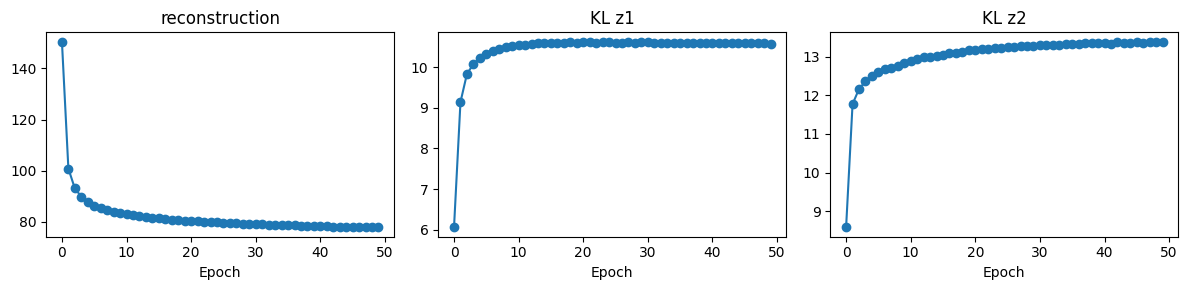

In [5]:
names = ['total', 'reconstruction', 'KL z1', 'KL z2']
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, index, title in zip(axes, [1, 2, 3], names[1:]):
    ax.plot([row[index] for row in history], marker='o')
    ax.set(title=title, xlabel='Epoch')
plt.tight_layout(); plt.show()

## Reconstruct and generate

Prior sampling is straightforward here because both priors are independent standard normals. We sample each latent separately and give both to the decoder.

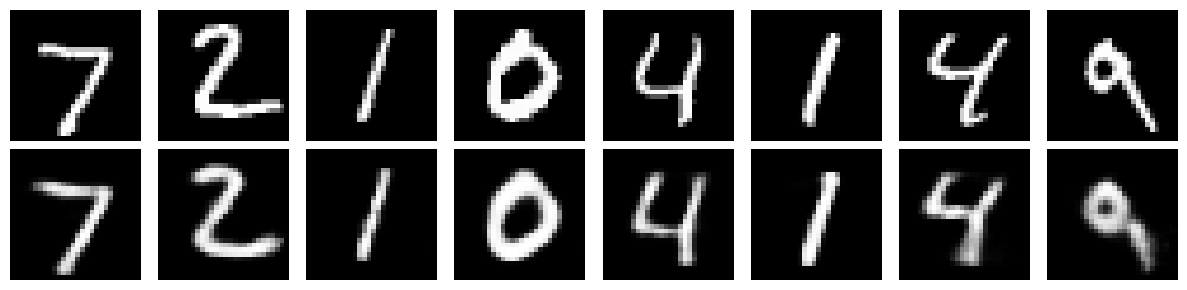

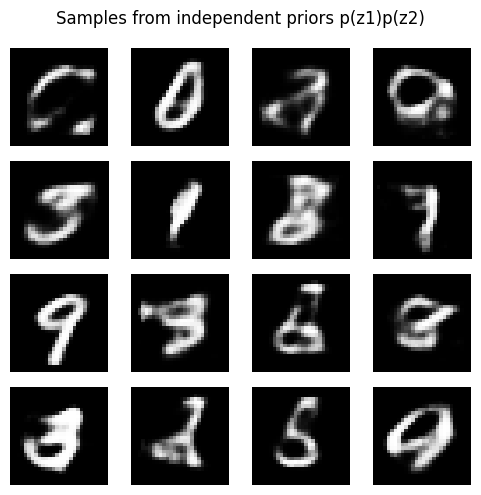

In [6]:
images, _ = next(iter(test_loader))
images = images[:8].to(device)
model.eval()
with torch.no_grad(): reconstruction, _ = model(images)
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(images[i, 0].cpu(), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(reconstruction[i, 0].cpu(), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('Input'); axes[1, 0].set_ylabel('Reconstruction')
plt.tight_layout(); plt.show()

with torch.no_grad():
    z1 = torch.randn(16, model.dim_z1, device=device)
    z2 = torch.randn(16, model.dim_z2, device=device)
    samples = model.decode(z1, z2).cpu()
fig, axes = plt.subplots(4, 4, figsize=(5, 5))
for ax, image in zip(axes.flat, samples):
    ax.imshow(image[0], cmap='gray'); ax.axis('off')
plt.suptitle('Samples from independent priors p(z1)p(z2)')
plt.tight_layout(); plt.show()

## Takeaways and knowledge check

Multiple latent variables only define a useful hierarchy when the probability model specifies how their distributions relate. Here `z1` and `z2` have independent priors and independent approximate posterior heads; both contribute to the observation. Multi-scale neural features and multiple random latent variables are related ideas, but they are not identical.

Hierarchical models can help with complex structure, but add computation and inference complexity. Monitor reconstruction, each KL term, latent statistics, sample diversity, and validation behavior. A standard VAE is often a sensible starting point when data or compute are limited. Latent levels are not guaranteed to become interpretable abstractions.

1. Why use multiple latent variables instead of one?
2. What does the factorization `p(z1)p(z2)` say about the prior?
3. Why monitor each KL contribution separately?
4. Does a multi-layer neural network automatically make a hierarchical VAE? Why?
5. What is one trade-off of adding latent levels?